# Fase II - Emoción desde el audio y recomendador híbrido

**Integrantes:** Darío Alexander Ojeda Muñoz · Alejandra Martínez Henao
**Proyecto Aplicado I - Maestría en Ciencia de Datos**

La Fase I mostró que la percepción emocional cambia entre personas y que existen dos perfiles de percepción. La Fase II responde la pregunta abierta en la presentación de avance:

> ¿Hasta dónde llega el proyecto usando solo anotaciones, y qué ganamos al incorporar audio preentrenado?

| Paso | Qué se hace |
|---|---|
| 1. Audio | 1.802 fragmentos MP3 de DEAM |
| 2. Representación | (a) descriptores **openSMILE** de DEAM (línea base) · (b) embeddings **AST** preentrenado en AudioSet (*transfer learning*) |
| 3. Adaptación | El modelo AST se **congela**; solo se entrena un regresor ligero encima |
| 4. Predicción | Valencia y activación de cada canción |
| 5. Comparación | Misma partición (80/20 estratificada por cuadrante) y mismas métricas |
| 6. Recomendación | Evaluación del recomendador híbrido usando las anotaciones humanas como verdad |

*Nota:* se planeó usar MERT, pero requiere ejecutar código remoto no verificado; se eligió AST (MIT), integrado en `transformers`, que también está preentrenado con música.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import fase2_modelos as f2
%matplotlib inline

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
COL = {"openSMILE (línea base)": "#7398B8", "AST (transfer learning)": "#E97A62", "openSMILE + AST": "#5EAAA4", "Promedio (sin audio)": "#C9D1DA"}

## 1. Representaciones del audio

- **openSMILE:** 260 descriptores por cuadro (energía, tono, espectro, MFCC…) que DEAM entrega precalculados; se resumen por canción con media y desviación → 520 variables.
- **AST:** cada canción se divide en hasta 6 fragmentos de 10 s; el transformer preentrenado devuelve un vector de 768 valores por fragmento y se resume con media y desviación → 1.536 variables.

Las representaciones se generan con `python src/fase2_audio.py --opensmile --ast` (≈ 25 min en GPU) y quedan guardadas en `outputs/`.

In [2]:
resultado = f2.run()   # entrena, compara y evalúa (≈ 3-5 min)
data = resultado["data"]
for nombre, X in data["representations"].items():
    print(f"{nombre:28s} {X.shape[1]:>5} variables")
print(f"Canciones: {len(data['static'])}  |  entrenamiento: {len(data['train_ids'])}  |  prueba: {len(data['test_ids'])}")

openSMILE (línea base)         520 variables
AST (transfer learning)       1536 variables
openSMILE + AST               2056 variables
Canciones: 1802  |  entrenamiento: 1441  |  prueba: 361


## 2. Predicción de valencia y activación

Para cada representación se prueban tres regresores (Ridge, SVR y gradient boosting). El modelo se elige **solo con validación cruzada de 5 particiones en entrenamiento**; el conjunto de prueba se usa una única vez al final.

In [3]:
tabla = resultado["results"].copy()
display(tabla.pivot_table(index=["representacion", "modelo"], columns="dimension", values=["RMSE_cv", "R2", "RMSE"]).round(3))

R2                RMSE             RMSE_cv         
dimension                                 activacion valencia activacion valencia activacion valencia
representacion          modelo                                                                       
AST (transfer learning) Gradient boosting      0.657    0.529      0.723    0.802      0.817    0.794
                        Ridge                  0.684    0.505      0.694    0.822      0.805    0.800
                        SVR (RBF)              0.691    0.536      0.686    0.797      0.797    0.789
Promedio (sin audio)    Media                 -0.001   -0.001      1.235    1.169        NaN      NaN
openSMILE (línea base)  Gradient boosting      0.577    0.433      0.802    0.880      0.845    0.817
                        Ridge                  0.487    0.388      0.884    0.915      0.891    0.856
                        SVR (RBF)              0.531    0.356      0.845    0.938      0.868    0.862
openSMILE + AST         Gradient boosting      0.671    0.497      0.708    0.829      0.774    0.756
                        Ridge                  0.700    0.525      0.676    0.806      0.782    0.776
                        SVR (RBF)              0.694    0.527      0.683    0.804      0.773    0.776

,representacion,modelo,dimension,RMSE_cv,R2,RMSE,MAE
0,Promedio (sin audio),Media,valencia,NaN,-0.001,1.169,0.964
1,Promedio (sin audio),Media,activacion,NaN,-0.001,1.235,1.046
2,AST (transfer learning),SVR (RBF),activacion,0.797,0.691,0.686,0.538
3,AST (transfer learning),SVR (RBF),valencia,0.789,0.536,0.797,0.639
4,openSMILE (línea base),Gradient boosting,activacion,0.845,0.577,0.802,0.635
5,openSMILE (línea base),Gradient boosting,valencia,0.817,0.433,0.880,0.676
6,openSMILE + AST,SVR (RBF),activacion,0.773,0.694,0.683,0.537
7,openSMILE + AST,Gradient boosting,valencia,0.756,0.497,0.829,0.646


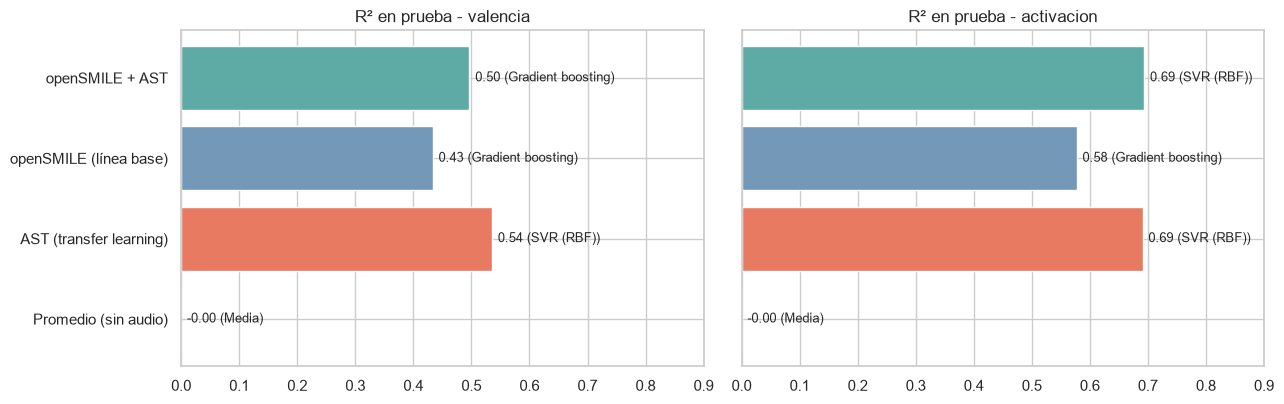

In [4]:
mejores = resultado["best"]
display(mejores[["representacion", "modelo", "dimension", "RMSE_cv", "R2", "RMSE", "MAE"]].round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, dim in zip(axes, ["valencia", "activacion"]):
    sub = mejores[mejores["dimension"] == dim]
    ax.barh(sub["representacion"], sub["R2"], color=[COL[r] for r in sub["representacion"]])
    for y, (r2, mod) in enumerate(zip(sub["R2"], sub["modelo"])):
        ax.text(max(r2, 0) + 0.01, y, f"{r2:.2f} ({mod})", va="center", fontsize=9)
    ax.set_title(f"R² en prueba - {dim}")
    ax.set_xlim(0, 0.9)
plt.tight_layout()
plt.show()

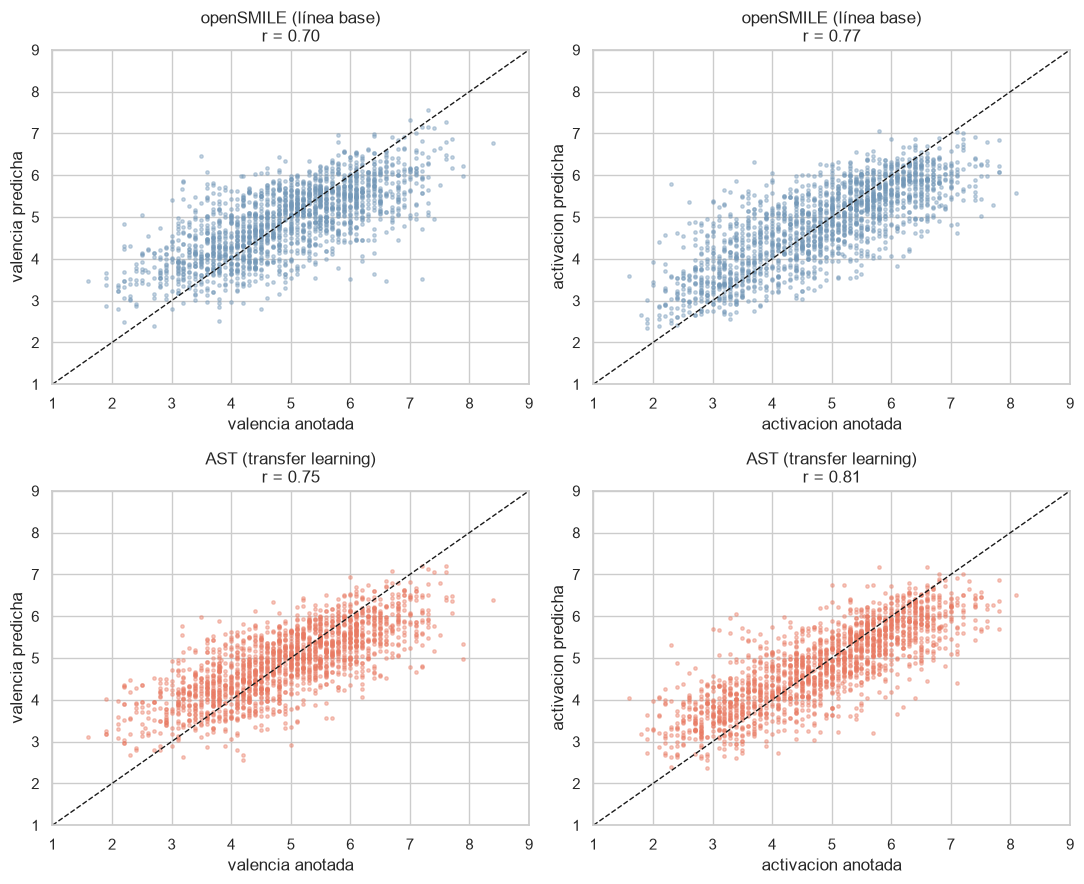

In [5]:
oof = resultado["oof"]
static = data["static"]
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for fila, rep in enumerate(["openSMILE (línea base)", "AST (transfer learning)"]):
    for col, (dim, real) in enumerate([("valencia", "valence_mean"), ("activacion", "arousal_mean")]):
        ax = axes[fila, col]
        ax.scatter(static[real], oof[rep][dim], s=6, alpha=0.4, color=COL[rep])
        ax.plot([1, 9], [1, 9], "k--", lw=1)
        r = np.corrcoef(static[real], oof[rep][dim])[0, 1]
        ax.set(xlim=(1, 9), ylim=(1, 9), xlabel=f"{dim} anotada", ylabel=f"{dim} predicha", title=f"{rep}\nr = {r:.2f}")
plt.tight_layout()
plt.show()

### Error por región emocional

Como el catálogo está desbalanceado (Fase I), el error se revisa por cuadrante: las regiones con pocas canciones suelen predecirse peor.

In [6]:
mejor_rep = "AST (transfer learning)"
err = pd.DataFrame({
    "cuadrante": static["quadrant"],
    "error_valencia": (oof[mejor_rep]["valencia"] - static["valence_mean"]).abs(),
    "error_activacion": (oof[mejor_rep]["activacion"] - static["arousal_mean"]).abs(),
    "cuadrante_predicho": f2.quadrant_of(oof[mejor_rep]["valencia"], oof[mejor_rep]["activacion"]),
})
por_cuadrante = err.groupby("cuadrante").agg(
    canciones=("error_valencia", "size"), MAE_valencia=("error_valencia", "mean"), MAE_activacion=("error_activacion", "mean"),
)
por_cuadrante["acierto_cuadrante"] = err.assign(ok=err["cuadrante"] == err["cuadrante_predicho"]).groupby("cuadrante")["ok"].mean()
display(por_cuadrante.round(3))
print("Exactitud global de cuadrante (fuera de muestra):", {k: f"{v:.1%}" for k, v in resultado["quadrant_acc"].items()})
display(pd.crosstab(err["cuadrante"], err["cuadrante_predicho"], rownames=["real"], colnames=["predicho"]))

,canciones,MAE_valencia,MAE_activacion,acierto_cuadrante
cuadrante,,,,
Negativa / alta,229,0.770,0.676,0.166
Negativa / baja,686,0.595,0.565,0.898
Positiva / alta,647,0.561,0.536,0.798
Positiva / baja,240,0.730,0.738,0.175


Exactitud global de cuadrante (fuera de muestra): {'openSMILE (línea base)': '64.5%', 'AST (transfer learning)': '67.3%', 'openSMILE + AST': '69.0%'}


predicho,Negativa / alta,Negativa / baja,Positiva / alta,Positiva / baja
real,,,,
Negativa / alta,38,79,98,14
Negativa / baja,8,616,31,31
Positiva / alta,32,54,516,45
Positiva / baja,7,122,69,42


## 3. Evaluación del recomendador (sin usuarios reales)

Se simula el caso real: **canciones sin anotar**, cuya emoción solo se conoce por el audio. Para cada una de las 8 emociones se recomiendan 10 canciones usando la emoción *predicha* (fuera de muestra) y se mide la calidad con la emoción *anotada* por humanos:

- **Acierto de cuadrante@10:** % de canciones recomendadas que realmente están en el cuadrante pedido.
- **Distancia real media:** qué tan lejos está, en realidad, cada canción de la emoción pedida.
- **Diversidad:** distancia media entre las canciones de una misma lista (más alta = lista más variada, pero también más dispersa respecto a la emoción).

*Aleatorio* es el piso y *Anotaciones humanas* el techo.

,acierto_cuadrante@10,distancia_real_media,diversidad_lista
sistema,,,
Aleatorio,0.250,2.925,2.144
Predicho con openSMILE (línea base),0.712,1.503,1.421
Predicho con AST (transfer learning),0.738,1.262,1.307
Predicho con openSMILE + AST,0.662,1.574,1.543
Anotaciones humanas (techo),1.000,0.365,0.342


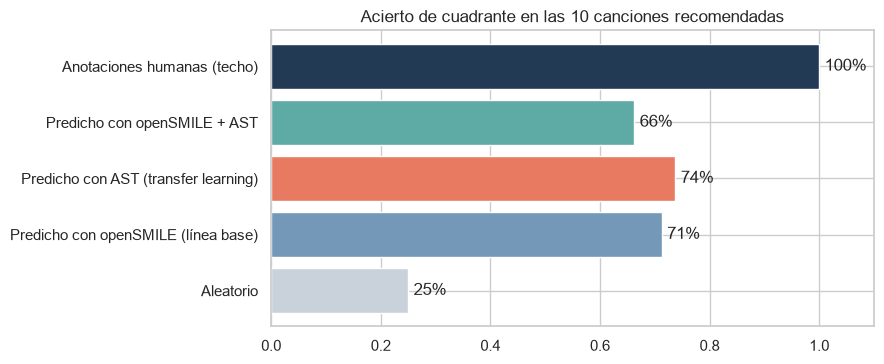

In [7]:
ev = resultado["recommender_eval"].set_index("sistema")
display(ev.round(3))
fig, ax = plt.subplots(figsize=(9, 3.8))
colores = ["#C9D1DA", "#7398B8", "#E97A62", "#5EAAA4", "#233A55"]
ax.barh(ev.index, ev["acierto_cuadrante@10"], color=colores[: len(ev)])
for y, v in enumerate(ev["acierto_cuadrante@10"]):
    ax.text(v + 0.01, y, f"{v:.0%}", va="center")
ax.set_xlim(0, 1.1)
ax.set_title("Acierto de cuadrante en las 10 canciones recomendadas")
plt.tight_layout()
plt.show()

### Efecto de la personalización por perfil

El sesgo medio de cada perfil de la Fase I desplaza la emoción percibida de cada canción. ¿Cuánto cambian las listas entre perfiles?

In [8]:
pers = resultado["personalization"]
display(pers.assign(solapamiento_listas=lambda d: (d["solapamiento_listas"] * 100).round(0).astype(int).astype(str) + " %"))
print(f"Solapamiento medio: {pers['solapamiento_listas'].mean():.0%} -> las listas comparten en promedio "
      f"{pers['solapamiento_listas'].mean() * 10:.1f} de 10 canciones entre perfiles")

,emocion,solapamiento_listas
0,alegre,0 %
1,energico,0 %
2,relajado,0 %
3,tranquilo,0 %
4,triste,0 %
5,melancolico,0 %
6,tenso,10 %
7,enojado,70 %


Solapamiento medio: 10% -> las listas comparten en promedio 1.0 de 10 canciones entre perfiles


## 4. Demo funcional

La aplicación `app/app.py` integra las dos fases:

```bash
streamlit run app/app.py
```

| Pestaña | Qué hace |
|---|---|
| 🎯 Recomendar por emoción | Elige emoción y perfil; muestra el mapa emocional y permite escuchar las canciones |
| 🧭 Descubre tu perfil | Califica 10 canciones y el árbol de la Fase I te asigna un perfil |
| 🛤️ Ruta emocional | Lista que avanza de una emoción a otra (principio iso) |
| 🎙️ Analiza una canción | Sube un MP3: AST + regresor predicen su emoción y recomiendan canciones parecidas |
| 📊 Resultados | Métricas de la Fase I y II |

## 5. Conclusiones de la Fase II

1. **El audio sí contiene la emoción, sobre todo la energía.** Con solo el audio se explica el 69 % de la variación de la activación y el 54 % de la valencia (R² en prueba con AST). Sin audio (predecir el promedio) el R² es 0.
2. **El transfer learning aporta valor real.** Con la misma partición y las mismas métricas, AST supera a los descriptores openSMILE en las dos dimensiones: valencia R² 0,43 → 0,54 y activación 0,58 → 0,69 (el error baja de 0,88 a 0,80 y de 0,80 a 0,69 puntos en la escala 1-9). Todo esto sin entrenar una red desde cero: el modelo preentrenado se dejó congelado.
3. **Combinar ambas representaciones no mejora de forma consistente:** iguala a AST en activación y queda por debajo en valencia; AST solo es la opción más simple y es la que usa la aplicación.
4. **La valencia es más difícil que la activación**, como reporta la literatura de reconocimiento de emociones musicales: la energía se oye (tempo, volumen, timbre), mientras que lo "positivo o negativo" depende más de la armonía, la letra y la cultura.
5. **El recomendador funciona con canciones sin anotar.** Con la emoción predicha por AST, el 74 % de las canciones recomendadas cae en el cuadrante correcto, frente al 25 % al azar y al 71 % con openSMILE; la distancia real a la emoción pedida baja de 2,9 (azar) a 1,3 puntos.
6. **La personalización cambia las listas:** entre los dos perfiles de la Fase I, las listas comparten en promedio solo 1 de cada 10 canciones.

### Limitaciones

- Las regiones con pocas canciones (negativa/alta: tenso, enojado) se predicen y se recomiendan peor; ampliar el catálogo en esa zona es prioritario.
- Se usó un único modelo preentrenado (AST) y fragmentos de 10 s; no se hizo *fine-tuning* de capas internas por la capacidad de la GPU (4 GB).
- MERT, el modelo usado por Music2Emo, no se evaluó porque requiere ejecutar código remoto no verificado.
- La evaluación del recomendador es **offline** (con anotaciones como verdad); falta medir satisfacción con usuarios reales.
- Los perfiles se derivan de trabajadores de crowdsourcing; el cuestionario de la app asigna un perfil con solo 10 canciones, lo que da una estimación aproximada.

### Trabajo futuro

- Piloto con usuarios reales usando la aplicación (satisfacción, relevancia percibida, diversidad).
- *Fine-tuning* parcial de AST o comparación con otros modelos musicales (MERT, CLAP).
- Usar la anotación dinámica (cada 0,5 s) para recomendar *fragmentos* y construir rutas emocionales dentro de una misma canción.
